# Importação de bibliotecas

- Pandas: dataframes
- Numpy: valores Nan
- CSV: abertura do arquivo para verificação de integridade dos dados
- Matplotlib.pyplot: Criação dos gráficos
- matplotlib.ticker: formatação dos valores nos gráficos

In [1]:
import pandas as pd
import numpy as np
import csv

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


# Verificação de Integridade

Para verificar se há registros quebrados antes de fazer o carregamento para o dataframe, o arquivo CSV foi aberto para leitura onde é extraido a quantidade de colunas do cabeçalho. 
Verificando linha a linha do CSV, se a quantidade de colunas da linha é igual a do cabeçalho. Esta função avalia a quantidade de itens a partir da separação por ','.

Se encontrado uma linha defeituosa, o seu indice é armazenado para que possa ser excluida nos próximos passos.

In [2]:
bad_lines = []
with open("googleplaystore.csv", newline='', encoding='utf-8') as arquivo_csv:

    leitura = csv.reader(arquivo_csv)
    cabecalho = next(leitura)
    qtd_colunas = len(cabecalho)

    for i, linha in enumerate(leitura): 
        if len(linha) != qtd_colunas:
            print(linha)
            bad_lines.append(i)

print(f"Linhas corrompidas: {bad_lines}")

['Life Made WI-Fi Touchscreen Photo Frame', '1.9', '19', '3.0M', '1,000+', 'Free', '0', 'Everyone', '', 'February 11, 2018', '1.0.19', '4.0 and up']
Linhas corrompidas: [10472]


# Criação do Dataframe

Agora, usando o pandas, é criado o dataframe a partir do arquivo csv.

In [3]:
df = pd.read_csv("googleplaystore.csv")

# Filtrando registros do Dataframe

Aqui são feitas a primeira filtragem, excluindo os indices defeituosos encontrados anteriormente. OBS.: "inplace = True" para alterar o dataframe 

In [4]:
df.drop(bad_lines, inplace=True)

### 1. Remova as linhas duplicadas ✅;

Ainda na filtragem, são removidas as linhas duplicadas

In [5]:
df.drop_duplicates(inplace=True)

# Formatando campos do Dataframe

Aqui são formatados cada um dos campos do Dataframe, para que possam ser aplicadas as operações corretas, de acordo com seu tipo.


Abaixo contém a função para formatar o "tamanho da instalação" que possui uma unidade entre 'K', 'M' e pode ser 'VARIES WITH DEVICE', tranformando-o no float correspondente a unidade (ou Nan).

In [6]:
def formatar_tamanho_instalacao(valor):

    if pd.isna(valor):
        return np.nan

    valor = valor.strip().upper()

    if valor == 'VARIES WITH DEVICE':
        return np.nan
    elif valor.endswith('K'):
        return float(valor[:-1]) * 1_000
    elif valor.endswith('M'):
        return float(valor[:-1]) * 1_000_000

    else:
        try:
            return float(valor) 
        except:
            return np.nan

É feita uma cópia do Dataframe, já que o Dataframe original pode ainda ser acessado, evitando efeitos inesperados ao longo do código, sendo uma boa prática. Em seguida, são feitas as conversões de cada campo (string) para o seu formato correto, e em caso de erro (errors='coerce') ou vazio, substituir por Nan.

In [7]:

df_original = df.copy() 


df['Category'] = df['Category'].replace('', np.nan).astype('category')

df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce').astype('Int64')

df['Size'] = df['Size'].apply(formatar_tamanho_instalacao)

df['Installs'] = df['Installs'].str.replace(r'[+,]', '', regex=True)
df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce').astype('Int64')

df['Type'] = df['Type'].replace('', np.nan).astype('category')

df['Price'] = df['Price'].str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df['Content Rating'] = df['Content Rating'].replace('', np.nan).astype('category')

df['Genres'] = df['Genres'].replace('', np.nan).astype('category') 

df['Last Updated'] = pd.to_datetime(df['Last Updated'], format='%B %d, %Y', errors='coerce')

df['Current Ver'] = df['Current Ver'].astype(str)

df['Android Ver'] = df['Android Ver'].astype(str)

# Agrupando registros por 'App', 'Categoria' e 'Genres'

Nos dataset, há registros de Apps repetidos. No entanto, para os resquisitos do desafio, não é demandado informação de períodos passados, e as colunas que queremos os dados, são os mais recentes. Portanto, em caso de registros de Apps repetidos, a coluna que garante que os dados são os mais recentes, é o de 'Reviews'. Isso porque é um dado que apenas pode ser incrementado com o passar do tempo, logo, mesmo que dois registros tenham datas diferentes para o mesmo App, não é necessário verificar diretamente a data para decidir qual manter. Isso porque de um dia para o outro, no pior dos casos, vão empatar na quantidade de reviews se nenhuma tiver sido feita. 

Então, a abordagem decidida para os registros repetidos foi agrupar os Apps pela maior quantidade de Reviews. No caso de empate, os dois critérios para decidir foi a data de update mais recente e após ela, a quantidade de instalações. No caso de haver esses 3 dados iguais, então é escolhido qualquer um dos registros repetidos (o primeiro da lista).

O detalhe é que o mesmo App pode possuir registros repetidos para diferenciar as categorias e generos, pois esses campos só suportam uma informação, mas um unico App pode possuir multiplos categorias e generos. Por isso, devere haver um registros repetido para cada um, diferenciando apenas por esses dois campos. Portanto, além de agrupar por App, também deve haver agrupamento por categoria e genero para preservar esses dados, que impactam diretamente nas análises futuras. 

É criado um grupo vazio, agrupamos o dataframe pelos 3 campos, e são verificados as maiores quantidades de reviews. Em seguida são feitas as condições desempate se houver mais de um registro.

In [8]:
grupos_filtrados = []

for _, grupo in df.groupby(['App', 'Category', 'Genres']):

    maior_reviews = grupo['Reviews'].max()
    grupo = grupo[grupo['Reviews'] == maior_reviews]

    if len(grupo) == 1:
        grupos_filtrados.append(grupo)
        continue

    data_mais_recente = grupo['Last Updated'].max()
    grupo = grupo[grupo['Last Updated'] == data_mais_recente]

    if len(grupo) == 1:
        grupos_filtrados.append(grupo)
        continue

    mais_instalado = grupo['Installs'].max()
    grupo = grupo[grupo['Installs'] == mais_instalado]

    if len(grupo) == 1:
        grupos_filtrados.append(grupo)
        continue
    else:
        grupos_filtrados.append(grupo.iloc[0])

df_mais_recentes_por_app_e_categoria = pd.concat(grupos_filtrados).reset_index(drop=True)

C:\Users\Rhamon-PC\AppData\Local\Temp\ipykernel_27296\3657211831.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, grupo in df.groupby(['App', 'Category', 'Genres']):


# Agrupando registros por 'App'

Em outras análises em que se pode desprezar as categorias, vamos ter um Dataframe onde garantiremos que haja um unico app, eliminando as repetições ocasionadas pela categoria e genres.

In [9]:
idx_maior_review_por_app = df_mais_recentes_por_app_e_categoria.groupby('App')['Reviews'].idxmax()

df_mais_recentes_por_app_agrupado = df_mais_recentes_por_app_e_categoria.loc[idx_maior_review_por_app].copy()

### 2. Faça um gráfico de barras contendo os top 5 apps por número de instalação ✅;

Com os dois dataframes com os dados formatados corretamente, e os registros filtrados, podemos fazer as analises pedidas. Para cada caso, copiamos o dataframe a ser utilizado, permitindo que excluamos os valores nulos sem que ocasione efeitos colaterais para as demais análises. 

Para obter o top 5 aps por número de instalação, basta ordenarmos por 'Installs' e definir head(5). Em seguida é criado o grafico comde barra usando o matplotlib, a partir do dataframe retornado. É configurado então as cores e formatação dos valores do gráfico.

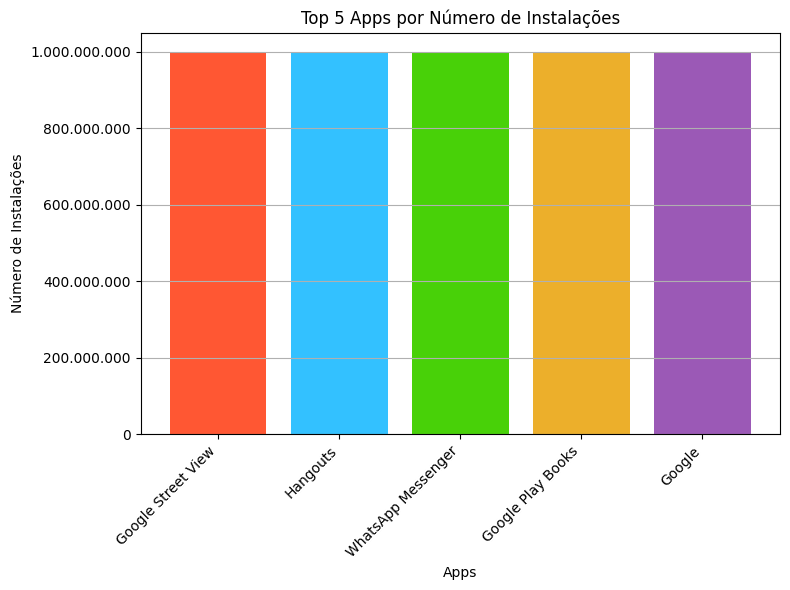

In [10]:
df = df_mais_recentes_por_app_agrupado.copy()
df = df.dropna(subset=['Installs'])

top_5_apps = df.sort_values(by='Installs', ascending=False).head(5)

cores = ['#FF5733', '#33C1FF', "#48D108", "#ECAF2B", '#9B59B6']

plt.figure(figsize=(8, 6))
plt.bar(top_5_apps['App'], top_5_apps['Installs'], color=cores)
plt.title('Top 5 Apps por Número de Instalações')
plt.xlabel('Apps')
plt.ylabel('Número de Instalações')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')

ax = plt.gca()
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x):,}'.replace(',', '.')))

plt.tight_layout()
plt.show()


### 3. Faça um gráfico de pizza (pie chart) mostrando as categorias de apps existentes no dataset de acordo com a frequência em que elas aparecem ✅;

Para mostrar a categorias de apps por frequencia, basta fazer a contagem do dataframe por 'Category'. Nesse caso é utilizado o dataframe que possuem as categorias separadas para cada registro.
É então plotado o grafico de pizza.

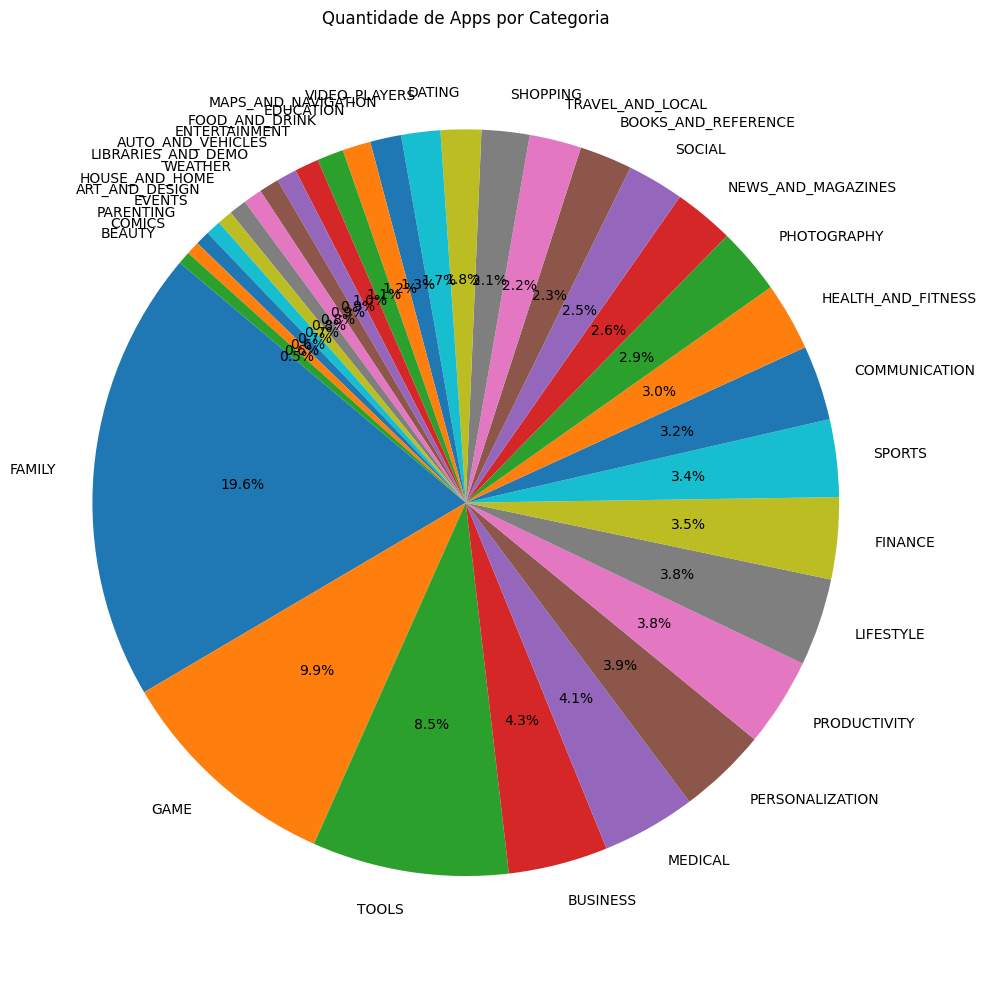

In [11]:
df = df_mais_recentes_por_app_e_categoria.copy()

df.dropna(subset=['Category'])
category_counts = df['Category'].value_counts()

plt.figure(figsize=(10, 10))
plt.pie(category_counts, labels=category_counts.index,
        autopct='%1.1f%%', startangle=140)
plt.title('Quantidade de Apps por Categoria')
plt.axis('equal')  
plt.tight_layout()
plt.show()

### 4. Mostre qual o app mais caro existente no dataset ✅;

O dataframe será com os apps agrupados, já que não queremos repetições de preço causados por app duplicados. Faz-se uma copia do dataframe para poder excluir os valores de preço que estão como Nan, sem provocar mudanças e então usando max(), achar o maior preço. É criado um dataframe com todos os registros que correspondem ao maior preço, (poderia haver mais de um), e são exibidos.


In [12]:
df = df_mais_recentes_por_app_agrupado.copy()

df.dropna(subset=['Price'])

preco_maximo = df['Price'].max()

apps_mais_caros = df[df['Price'] == preco_maximo]

print(f"Quantidade de itens mais caros encontrados: {len(apps_mais_caros)}\n")

print(apps_mais_caros[['App', 'Category', 'Genres', 'Reviews', 'Price']])

Quantidade de itens mais caros encontrados: 1

                           App   Category     Genres  Reviews  Price
5373  I'm Rich - Trump Edition  LIFESTYLE  Lifestyle      275  400.0


# 5. Mostre quantos apps são classificados como 'Mature 17+' ✅;

Dataframe de apps unicos, sao extraidos os que tem 'Content Rating' como 'Mature 17+', e é printada a quantidade de linhas do dataframe que são referentes a quantidade de apps encontrados.

In [13]:
df = df_mais_recentes_por_app_agrupado

mature_apps = df[df['Content Rating'] == 'Mature 17+']

print(f"Total de apps 'Mature 17+': {mature_apps.shape[0]}")

Total de apps 'Mature 17+': 393


### 6. Mostre o top 10 apps por número de reviews bem como o respectivo número de reviews. Ordene a lista de forma decrescente or número de reviews ✅;

Copia o dataframe de apps agrupados e ordena de forma decrescente por quantidade de reviews. São mantidos apenas os 10 primeiros e, em seguida, exibidos por App e Reviews.

In [14]:
df = df_mais_recentes_por_app_agrupado.copy()

df.dropna(subset=['Reviews'])

top_10_reviews = df.sort_values(by='Reviews', ascending=False).head(10)

print("Top 10 apps por número de reviews:")
print(top_10_reviews[['App', 'Reviews']])

Top 10 apps por número de reviews:
                                                    App   Reviews
4361                                           Facebook  78158306
9125                                 WhatsApp Messenger  69119316
5446                                          Instagram  66577446
6218           Messenger – Text and Video Chat for Free  56646578
2584                                     Clash of Clans  44893888
2594            Clean Master- Space Cleaner & Antivirus  42916526
8152                                     Subway Surfers  27725352
9309                                            YouTube  25655305
7791  Security Master - Antivirus, VPN, AppLock, Boo...  24900999
2580                                       Clash Royale  23136735


### 7. Crie pelo menos mais 2 cálculos sobre o dataset e apresente um em formato de lista e outro em formato de valor. Por exemplo: "top 10 apps por número de reviews" e "o app mais caro existente no dataset" ✅; 

As duas análises escolhidas foram:
- Top 10 Apps que maiores rendas geradas
- O jogo com mais reviews

É utilizado o dataframe de apps agrupados, e a renda é calculada acessando cada registro multiplicando preço por quantidade de instalações. Em seguida, são ordenadas e reduzidos aos 10 do topo. 

In [15]:
df = df_mais_recentes_por_app_agrupado.copy()

df.dropna(subset=['Reviews', 'Price'])

df['Renda'] = df['Price'] * df['Installs']

top10_renda = df.sort_values('Renda', ascending=False).head(10)

print(top10_renda[['App', 'Price', 'Installs', 'Renda']])

                                App   Price  Installs       Renda
6264                      Minecraft    6.99  10000000  69900000.0
5367                      I am rich  399.99    100000  39999000.0
5347              I Am Rich Premium  399.99     50000  19999500.0
5242                  Hitman Sniper    0.99  10000000   9900000.0
5001  Grand Theft Auto: San Andreas    6.99   1000000   6990000.0
7924        Sleep as Android Unlock    5.99   1000000   5990000.0
4370            Facetune - For Free    5.99   1000000   5990000.0
3459            DraStic DS Emulator    4.99   1000000   4990000.0
5373       I'm Rich - Trump Edition  400.00     10000   4000000.0
5363                 I am Rich Plus  399.99     10000   3999900.0


Cria a cópia do dataframe e filtra por categoria igual a Jogo. No final ordena e mantem apenas o maior.

In [16]:
df = df_mais_recentes_por_app_agrupado.copy()

df.dropna(subset=['Category'])

df_jogos = df[df['Category'] == 'GAME']

app_mais_popular = df_jogos.sort_values(by='Reviews', ascending=False).head(1)

print(app_mais_popular[['App', 'Reviews', 'Rating', 'Installs']])

                 App   Reviews  Rating   Installs
2584  Clash of Clans  44893888     4.6  100000000


### 8- Crie pelo menos outras 2 formas gráficas de exibição dos indicadores acima utilizando a biblioteca Matplotlib. ✅; 

Com os dois dataframes criados anteriormente, são criados os dois graficos com o matplotlib.

Para o top 10, foi utilzado o grafico de barras horizontal, definindo qual cores para cada barra, exibindo o correspondente valor de cada e formatando os valores do eixo X para corresponderem a preço (dolar). 

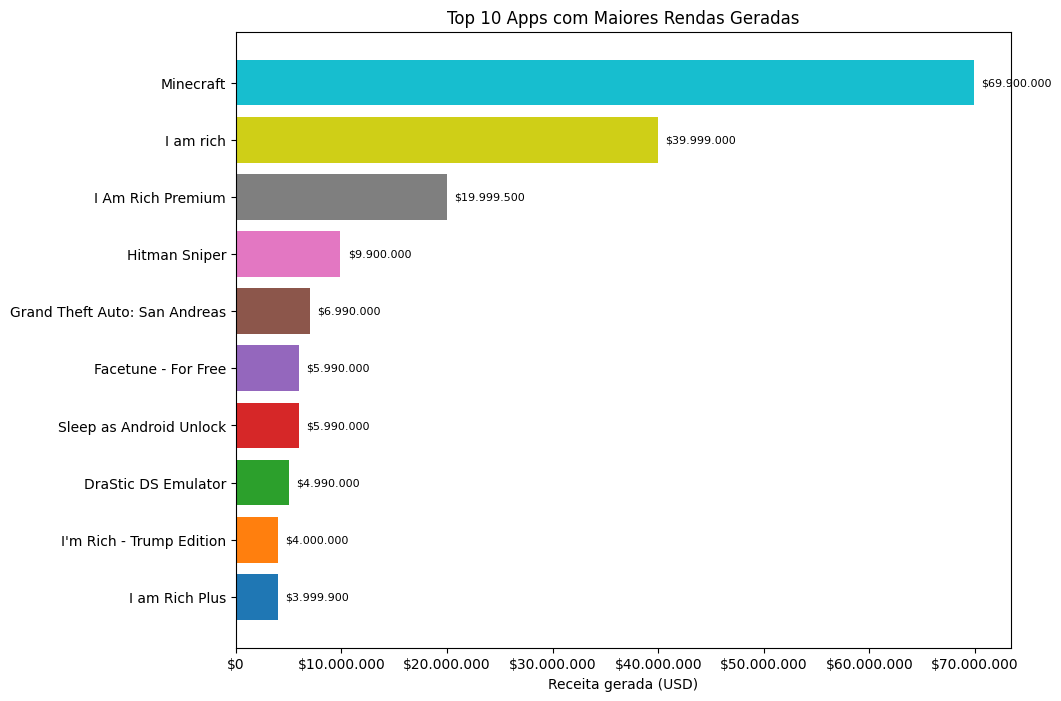

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

top10_renda = top10_renda.sort_values(by='Renda', ascending=True).reset_index(drop=True)

colors = [
    '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
    '#8c564b', '#e377c2', '#7f7f7f', "#cfcf17", '#17becf'
]

plt.figure(figsize=(10, 8))

for i, row in top10_renda.iterrows():
    app = row['App']
    width = row['Renda']
    y = i

    plt.barh(y, width, color=colors[i], zorder=2)

    plt.text(width + max(top10_renda['Renda']) * 0.01, y, f'${width:,.0f}'.replace(',', '.'),
             va='center', fontsize=8, color='black', zorder=3)

plt.xlabel('Receita gerada (USD)')
plt.title('Top 10 Apps com Maiores Rendas Geradas')

plt.yticks(np.arange(len(top10_renda)), top10_renda['App'], fontsize=10)

def formatar_dolar_milhao(x, pos):
    return f'${int(x):,.0f}'.replace(',', '.')

formatter = ticker.FuncFormatter(formatar_dolar_milhao)
plt.gca().xaxis.set_major_formatter(formatter)
plt.show()

Para o jogo com mais reviews, uma unica barra que foi formatada para reduzir seu tamanho, exbindo o seu valor correspondente, e os eixos mostrados no formato inteiro, separados por ponto. Foi definido também um valor limite para o grafico, afim de uma melhor visualização.

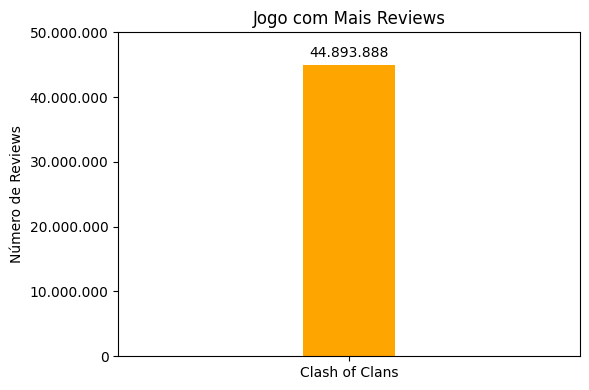

In [18]:
app = app_mais_popular['App'].values[0]
reviews = app_mais_popular['Reviews'].values[0]

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar([0], [reviews], color='orange', width=0.2)

ax.set_xlim(-0.5, 0.5)

ax.set_xticks([0])
ax.set_xticklabels([app])
ax.set_ylim(0, 50_000_000)
ax.set_ylabel('Número de Reviews')
ax.set_title('Jogo com Mais Reviews')

def formatar_milhar(x, pos):
    return f'{int(x):,}'.replace(',', '.')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(formatar_milhar))

ax.text(0, reviews + reviews * 0.02, f'{reviews:,}'.replace(',', '.'), 
        ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()